In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score

Assignment Problems: Day 13

The following problems require access to the file named ‘Dataset_Day13.csv’, provided with this assignment.
This is the Iris dataset. The dataset 150 data points.

It includes three iris species with 50 samples each as well as some properties about each flower. One flower species is linearly separable from the other two, but the other two are not linearly separable from each other.

The columns in this dataset are:

Id, SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm, Species

* Firstly, treat all outliers and missing values in the dataset.
* Complete all basic data descriptive statistics by Species

In [61]:
d = pd.read_csv("Dataset_Day13.csv")
d.drop("Id",axis=1,inplace = True)

# Scalling of data
scaled_data = pd.DataFrame()
for i in ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']:
    scaled_data[i] = (d[i]-d[i].mean())/d[i].std()

# ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
# Outlier removal
outlier = pd.DataFrame(columns = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm'])
outlier = scaled_data[(scaled_data["SepalLengthCm"]>3)|(scaled_data["SepalLengthCm"]<-3)|
                   (scaled_data["SepalWidthCm"]>3)|(scaled_data["SepalWidthCm"]<-3)|
                   (scaled_data["PetalLengthCm"]>3)|(scaled_data["PetalLengthCm"]<-3)|
                   (scaled_data["PetalWidthCm"]>3)|(scaled_data["PetalWidthCm"]<-3)]
data = d.drop(outlier.index,axis=0)
d.drop(outlier.index,axis=0,inplace = True)
print("\nno. of Outlier",len(outlier), "\n% of Outlier = ", str(len(outlier)/len(scaled_data)*100))
data.drop("Species", axis = 1,inplace = True)
data.info(), data.describe()


no. of Outlier 1 
% of Outlier =  0.6666666666666667
<class 'pandas.core.frame.DataFrame'>
Int64Index: 149 entries, 0 to 149
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  149 non-null    float64
 1   SepalWidthCm   149 non-null    float64
 2   PetalLengthCm  149 non-null    float64
 3   PetalWidthCm   149 non-null    float64
dtypes: float64(4)
memory usage: 5.8 KB


(None,
        SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
 count     149.000000    149.000000     149.000000    149.000000
 mean        5.844295      3.044966       3.773826      1.204027
 std         0.830775      0.420655       1.760543      0.762896
 min         4.300000      2.000000       1.000000      0.100000
 25%         5.100000      2.800000       1.600000      0.300000
 50%         5.800000      3.000000       4.400000      1.300000
 75%         6.400000      3.300000       5.100000      1.800000
 max         7.900000      4.200000       6.900000      2.500000)

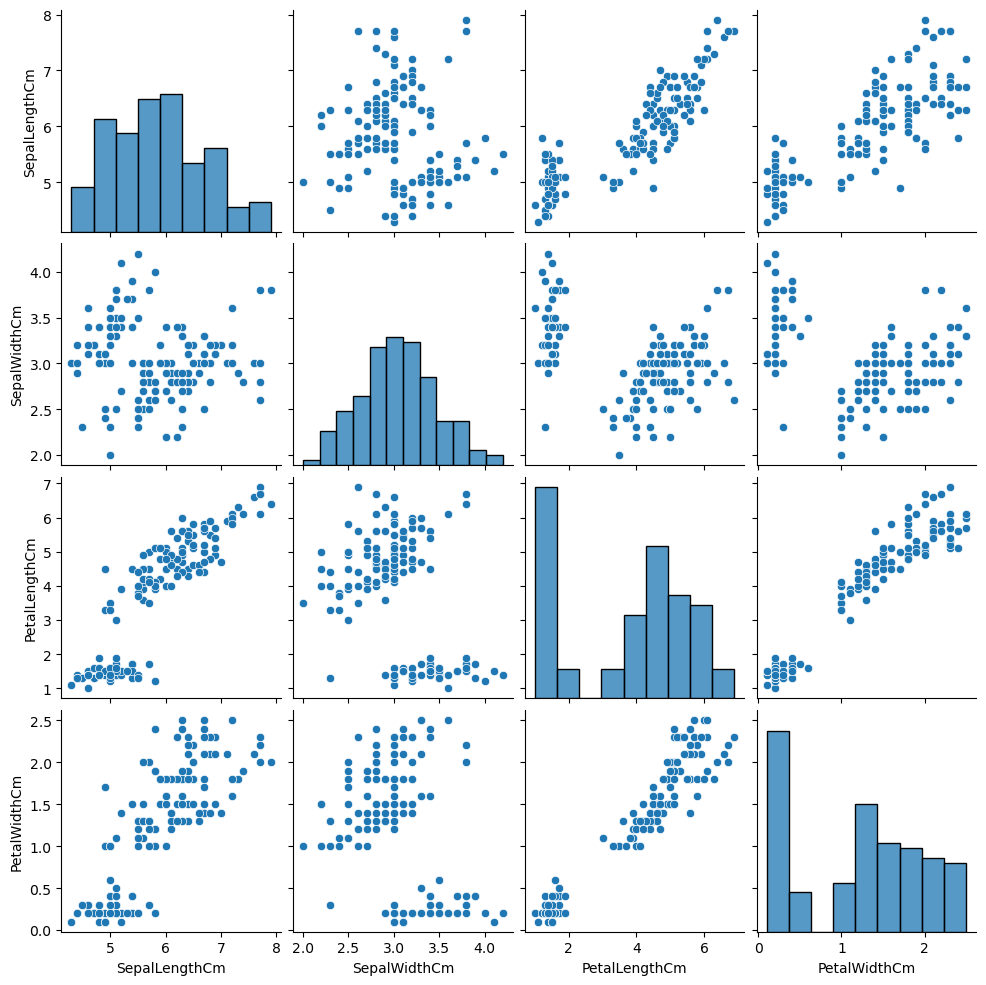

In [23]:
sns.pairplot(data)

* Use the Sepal Length , Sepal Width, Petal Length and Petal Width to find K-Means clusters.

In [67]:
model = KMeans(n_clusters = 3, n_init = 25, random_state = 1234)
model = model.fit(data)
cl = model.labels_ # cluster labels
cWCSS = model.inertia_

C:\Users\nikhi\anaconda3\envs\env1\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [69]:
display(pd.Series(model.labels_).value_counts().sort_index(), 
        (pd.Series(model.labels_).value_counts().sort_index())/len(data))
cluster_centers = pd.DataFrame(model.cluster_centers_, columns = data.columns)
display(cluster_centers)
cluster_centers_unscaled = pd.DataFrame()
for i in data.columns :
    cluster_centers_unscaled[i] = (cluster_centers[i]*data[i].std())+data[i].mean()
display(cluster_centers_unscaled)

0    49
1    38
2    62
dtype: int64

0    0.328859
1    0.255034
2    0.416107
dtype: float64

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,4.991837,3.397959,1.463265,0.240816
1,6.850000,3.073684,5.742105,2.071053
2,5.901613,2.748387,4.393548,1.433871


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,9.991388,4.474336,6.349968,1.387745
1,11.535103,4.337928,13.883051,2.784025
2,10.747207,4.201090,11.508858,2.297922


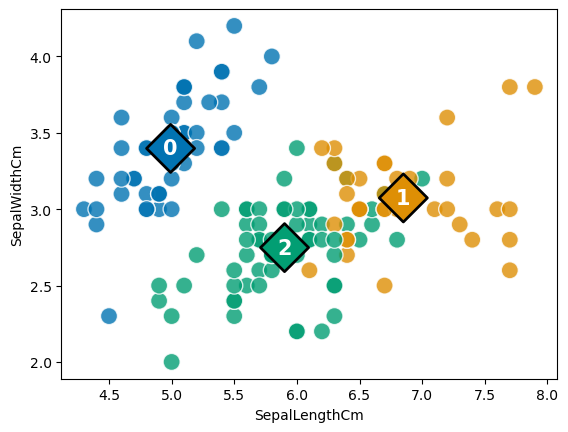

In [53]:
ax = sns.scatterplot(data = data,x = 'SepalLengthCm',y = 'SepalWidthCm',hue = model.labels_,
                     palette = 'colorblind', alpha = 0.8, s = 150, legend = False)
ax = sns.scatterplot(data = cluster_centers, x = 'SepalLengthCm',y = 'SepalWidthCm', 
                     hue = cluster_centers.index, palette = 'colorblind', s = 600, marker = 'D',
                     ec = 'black', legend = False)
for i in range(len(cluster_centers)):
               plt.text(x = cluster_centers.SepalLengthCm[i], y = cluster_centers.SepalWidthCm[i], s = i, 
                        horizontalalignment='center', verticalalignment='center', size = 15,
                        weight = 'bold', color = 'white')

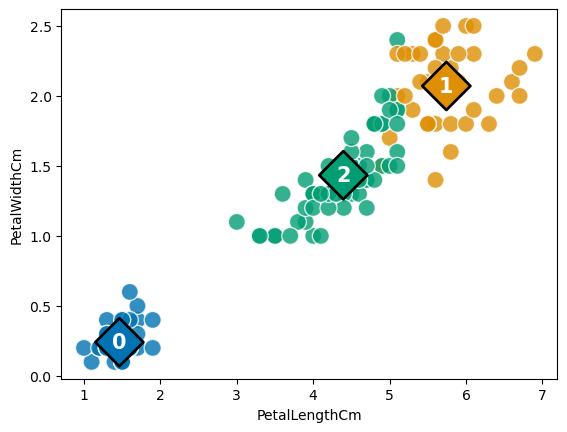

In [54]:
ax = sns.scatterplot(data = data,x = 'PetalLengthCm',y = 'PetalWidthCm',hue = model.labels_,
                     palette = 'colorblind', alpha = 0.8, s = 150, legend = False)
ax = sns.scatterplot(data = cluster_centers, x = 'PetalLengthCm',y = 'PetalWidthCm', 
                     hue = cluster_centers.index, palette = 'colorblind', s = 600, marker = 'D',
                     ec = 'black', legend = False)
for i in range(len(cluster_centers)):
               plt.text(x = cluster_centers.PetalLengthCm[i], y = cluster_centers.PetalWidthCm[i], s = i, 
                        horizontalalignment='center', verticalalignment='center', size = 15,
                        weight = 'bold', color = 'white')

* Find the optimum cluster number based on, elbow method, silhouette method and Calinski Harabasz Score.

In [55]:
wcss = []
silhouette = []
calinski = []
for k in range(2, 11):
    model = KMeans(n_clusters = k, n_init = 25, random_state = 1234)
    model.fit(data)
    wcss.append(model.inertia_)
    silhouette.append(silhouette_score(data, model.labels_))
    calinski.append(calinski_harabasz_score(data, model.labels_))

wcss_series = pd.Series(wcss, index = range(2, 11))
silhouette_series = pd.Series(silhouette, index = range(2, 11))
calinski_series = pd.Series(calinski, index = range(2, 11))

C:\Users\nikhi\anaconda3\envs\env1\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\nikhi\anaconda3\envs\env1\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\nikhi\anaconda3\envs\env1\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\nikhi\anaconda3\envs\env1\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans 

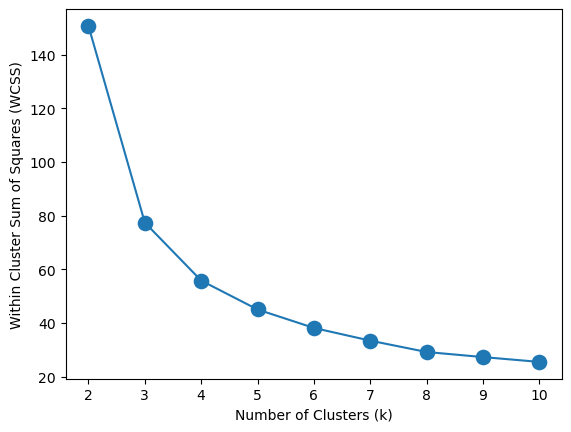

In [62]:
#Elbow Method
ax = sns.lineplot(y = wcss_series, x = wcss_series.index)
ax = sns.scatterplot(y = wcss_series, x = wcss_series.index, s = 150)
ax = ax.set(xlabel = 'Number of Clusters (k)', 
            ylabel = 'Within Cluster Sum of Squares (WCSS)')

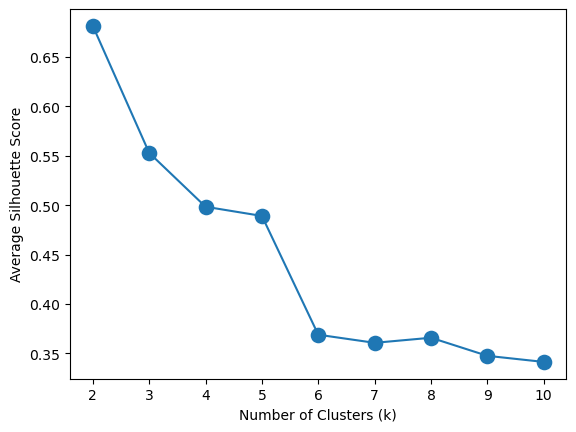

In [63]:
# Silhouette Method
ax = sns.lineplot(y = silhouette_series, x = silhouette_series.index)
ax = sns.scatterplot(y = silhouette_series, x = silhouette_series.index, s = 150)
ax = ax.set(xlabel = 'Number of Clusters (k)', 
            ylabel = 'Average Silhouette Score')

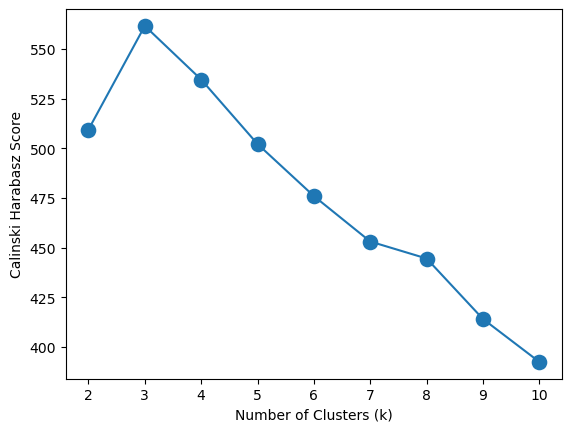

In [64]:
# Calinski Harabasz Score Method
ax = sns.lineplot(y = calinski_series, x = calinski_series.index)
ax = sns.scatterplot(y = calinski_series, x = calinski_series.index, s = 150)
ax = ax.set(xlabel = 'Number of Clusters (k)', 
            ylabel = 'Calinski Harabasz Score')

In [128]:
model = KMeans(n_clusters = 3, n_init = 25, random_state = 1234)
model = model.fit(data)
cl = model.labels_

pred = pd.DataFrame({"species":cl})
test = pd.DataFrame(columns = ["species"])
for i in d["Species"]:
    if i == "Iris-setosa":
        test = pd.concat([pd.DataFrame([1], columns=pred.columns), test], ignore_index=True)
    elif i == "Iris-virginica":
        test = pd.concat([pd.DataFrame([0], columns=pred.columns), test], ignore_index=True)
    else:
        test = pd.concat([pd.DataFrame([2], columns=pred.columns), test], ignore_index=True)
# Iris-versicolor
a = 0
for i in range(0,len(d)):
    if pred["species"][i] == test["species"][i]:
        a = a + 1
a = (a/len(d))*100
print("Accuracy = ", a)

C:\Users\nikhi\anaconda3\envs\env1\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Accuracy =  87.91946308724832


In [150]:
d = pd.read_csv("Dataset_Day13.csv")
scaled_data = pd.DataFrame(columns = ["s", "p"])
da1 = pd.DataFrame(columns = ["s", "p"])
da1["s"] = d["SepalLengthCm"]*d["SepalWidthCm"]
da1["p"] = d["PetalLengthCm"]*d["PetalWidthCm"]

for i in ["s", "p"]:
    scaled_data[i] = (da1[i]-da1[i].mean())/da1[i].std()
    
model = KMeans(n_clusters = 3, n_init = 25, random_state = 1234)
model = model.fit(scaled_data)
cl = model.labels_

pred = pd.DataFrame({"species":cl})
test = pd.DataFrame(columns = ["species"])
for i in d["Species"]:
    if i == "Iris-setosa":
        test = pd.concat([pd.DataFrame([1], columns=pred.columns), test], ignore_index=True)
    elif i == "Iris-virginica":
        test = pd.concat([pd.DataFrame([2], columns=pred.columns), test], ignore_index=True)
    else:
        test = pd.concat([pd.DataFrame([0], columns=pred.columns), test], ignore_index=True)
# Iris-versicolor
a = 0
for i in range(0,len(d)):
    if pred["species"][i] == test["species"][i]:
        a = a + 1
a = (a/len(d))*100
print("Accuracy = ", a)

C:\Users\nikhi\anaconda3\envs\env1\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Accuracy =  81.33333333333333


Name - Nikhil Khatri

SIC - 21BCSA92